# MSCS 634 - Lab Assignment 5

**Name:** Chun-Shuo Sheu
**Course:** MSCS 634 - Big Data & Data Mining
**Lab Assignment:** Lab 5 - Clustering Analysis using Hierarchical and DBSCAN Clustering on the Wine Dataset

## Overview
In this lab we explore two clustering families that make very different assumptions about what a
cluster *is*:

- **Agglomerative Hierarchical Clustering** - builds a nested tree of merges from the bottom up, so
  the number of clusters is a decision made *after* the model is fit by cutting the dendrogram.
- **DBSCAN** - defines clusters as dense regions separated by sparse ones, discovers the number of
  clusters on its own, and explicitly labels low-density points as **noise**.

Both are applied to the 13-feature Wine dataset from `sklearn`. We tune `n_clusters` and the linkage
method for the hierarchical model, and `eps` / `min_samples` for DBSCAN, then evaluate every result
with three metrics:

- **Silhouette Score** - internal measure of cluster compactness and separation (no labels used).
- **Homogeneity Score** - external: does each cluster contain only members of one true class?
- **Completeness Score** - external: are all members of a true class placed in the same cluster?

The **Adjusted Rand Index (ARI)** is also reported as a single-number summary of agreement with the
ground-truth cultivars, and a 2D PCA projection is used for all visualizations.

## Step 1: Data Preparation and Exploration

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (silhouette_score, homogeneity_score,
                             completeness_score, adjusted_rand_score)

from scipy.cluster.hierarchy import dendrogram, linkage, cophenet
from scipy.spatial.distance import pdist

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

In [2]:
# Load the Wine dataset
wine = load_wine()
X = wine.data
y = wine.target
feature_names = wine.feature_names
target_names = wine.target_names

df = pd.DataFrame(X, columns=feature_names)
df['target'] = y

print(f"Dataset shape: {df.shape}")
print(f"Number of features: {len(feature_names)}")
print(f"Number of classes: {len(target_names)}")
print(f"Class names: {list(target_names)}")
df.head()

Dataset shape: (178, 14)
Number of features: 13
Number of classes: 3
Class names: [np.str_('class_0'), np.str_('class_1'), np.str_('class_2')]


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0


In [3]:
# Structure and data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null    float64
 13  target          

In [4]:
# Feature descriptive statistics
df[feature_names].describe()

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
count,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000,178.000000
mean,13.000618,2.336348,2.366517,19.494944,99.741573,2.295112,2.029270,0.361854,1.590899,5.058090,0.957449,2.611685,746.893258
std,0.811827,1.117146,0.274344,3.339564,14.282484,0.625851,0.998859,0.124453,0.572359,2.318286,0.228572,0.709990,314.907474
min,11.030000,0.740000,1.360000,10.600000,70.000000,0.980000,0.340000,0.130000,0.410000,1.280000,0.480000,1.270000,278.000000
25%,12.362500,1.602500,2.210000,17.200000,88.000000,1.742500,1.205000,0.270000,1.250000,3.220000,0.782500,1.937500,500.500000
50%,13.050000,1.865000,2.360000,19.500000,98.000000,2.355000,2.135000,0.340000,1.555000,4.690000,0.965000,2.780000,673.500000
75%,13.677500,3.082500,2.557500,21.500000,107.000000,2.800000,2.875000,0.437500,1.950000,6.200000,1.120000,3.170000,985.000000
max,14.830000,5.800000,3.230000,30.000000,162.000000,3.880000,5.080000,0.660000,3.580000,13.000000,1.710000,4.000000,1680.000000


In [5]:
# Class distribution and data-quality checks
class_counts = pd.Series(y).value_counts().sort_index()
class_counts.index = [target_names[i] for i in class_counts.index]
print("Class distribution:")
print(class_counts, "\n")

print(f"Missing values: {int(df.isna().sum().sum())}")
print(f"Duplicate rows: {int(df.duplicated().sum())}")

Class distribution:
class_0    59
class_1    71
class_2    48
Name: count, dtype: int64 

Missing values: 0
Duplicate rows: 0


### Why standardization is mandatory here

The Wine features live on wildly different scales - `proline` runs into the *hundreds* while
`nonflavanoid_phenols` sits below 1. Both hierarchical clustering (Euclidean/Ward) and DBSCAN
(the `eps` radius) are distance-based, so without scaling `proline` alone would dictate every
distance and the other 12 features would be effectively ignored.

In [6]:
# Show the scale problem before fixing it
print("Feature std. deviations on the raw data (sorted):")
print(df[feature_names].std().sort_values(ascending=False).round(3))

Feature std. deviations on the raw data (sorted):
proline                         314.907
magnesium                        14.282
alcalinity_of_ash                 3.340
color_intensity                   2.318
malic_acid                        1.117
flavanoids                        0.999
alcohol                           0.812
od280/od315_of_diluted_wines      0.710
total_phenols                     0.626
proanthocyanins                   0.572
ash                               0.274
hue                               0.229
nonflavanoid_phenols              0.124
dtype: float64


In [7]:
# Standardize features using z-score normalization
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Mean of scaled features (approx 0): {X_scaled.mean(axis=0).round(4)}")
print(f"Std  of scaled features (approx 1): {X_scaled.std(axis=0).round(4)}")

Mean of scaled features (approx 0): [ 0.  0. -0. -0. -0. -0.  0. -0. -0. -0.  0.  0. -0.]
Std  of scaled features (approx 1): [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [8]:
# 2D PCA projection - used ONLY for plotting. All clustering and all metrics
# are computed in the full 13-dimensional standardized space.
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_pca = pca.fit_transform(X_scaled)

print(f"Explained variance ratio (PC1, PC2): {pca.explained_variance_ratio_.round(4)}")
print(f"Total variance captured by 2 PCs: {pca.explained_variance_ratio_.sum():.2%}")

Explained variance ratio (PC1, PC2): [0.362  0.1921]
Total variance captured by 2 PCs: 55.41%


In [9]:
# Helper used by every scatter plot in this notebook.
# Noise points (label -1, produced by DBSCAN) are drawn as red X markers.
def plot_clusters(ax, labels, title):
    noise = labels == -1
    if noise.any():
        ax.scatter(X_pca[noise, 0], X_pca[noise, 1], c='red', marker='x',
                   s=55, linewidths=1.6, label=f'Noise (n={noise.sum()})')
    pts = ~noise
    ax.scatter(X_pca[pts, 0], X_pca[pts, 1], c=labels[pts], cmap='viridis',
               s=45, edgecolors='k', alpha=0.85)
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('PC 1')
    ax.set_ylabel('PC 2')
    ax.grid(alpha=0.3)
    if noise.any():
        ax.legend(loc='upper right', fontsize=8)


# Metric bundle reported for every clustering in this lab.
def score(labels, X_ref=X_scaled, y_ref=y):
    n_clusters = len(set(labels) - {-1})
    n_noise = int((labels == -1).sum())
    out = {'n_clusters': n_clusters, 'n_noise': n_noise}
    # Silhouette on all points, treating noise as its own label. This is the
    # conservative reading: a run that dumps most points into noise is punished.
    out['silhouette'] = silhouette_score(X_ref, labels) if len(set(labels)) > 1 else np.nan
    # Silhouette on the clustered points only (undefined if fewer than 2 clusters remain).
    keep = labels != -1
    out['silhouette_no_noise'] = (silhouette_score(X_ref[keep], labels[keep])
                                  if n_clusters > 1 else np.nan)
    out['homogeneity'] = homogeneity_score(y_ref, labels)
    out['completeness'] = completeness_score(y_ref, labels)
    out['ari'] = adjusted_rand_score(y_ref, labels)
    return out

## Step 2: Hierarchical Clustering

Agglomerative clustering starts with every sample as its own cluster and repeatedly merges the two
closest clusters. "Closest" depends on the **linkage** rule, so the linkage choice matters as much as
`n_clusters`. We sweep four linkage methods across `n_clusters = 2 ... 6`.

In [10]:
# Sweep linkage method x n_clusters
rows = []
for linkage_method in ['ward', 'complete', 'average', 'single']:
    for k in range(2, 7):
        labels = AgglomerativeClustering(n_clusters=k, linkage=linkage_method).fit_predict(X_scaled)
        rows.append({'linkage': linkage_method, 'n_clusters': k, **score(labels)})

hier_results = pd.DataFrame(rows)[['linkage', 'n_clusters', 'silhouette',
                                   'homogeneity', 'completeness', 'ari']]
hier_results.round(4)

,linkage,n_clusters,silhouette,homogeneity,completeness,ari
0,ward,2,0.2670,0.4441,0.7745,0.4394
1,ward,3,0.2774,0.7904,0.7825,0.7899
2,ward,4,0.2258,0.7904,0.6490,0.6568
3,ward,5,0.1867,0.8106,0.5762,0.5830
4,ward,6,0.1797,0.8348,0.5530,0.5757
5,complete,2,0.1619,0.2857,0.4647,0.2953
6,complete,3,0.2038,0.6157,0.6130,0.5771
7,complete,4,0.1938,0.7214,0.6169,0.6427
8,complete,5,0.1884,0.8159,0.6241,0.6776
9,complete,6,0.1755,0.8165,0.6044,0.6631


In [11]:
# Best configuration by silhouette (the only metric that needs no ground truth)
best_hier = hier_results.loc[[hier_results['silhouette'].idxmax()]]
print("Best hierarchical configuration by Silhouette Score:")
best_hier.round(4)

Best hierarchical configuration by Silhouette Score:


,linkage,n_clusters,silhouette,homogeneity,completeness,ari
1,ward,3,0.2774,0.7904,0.7825,0.7899


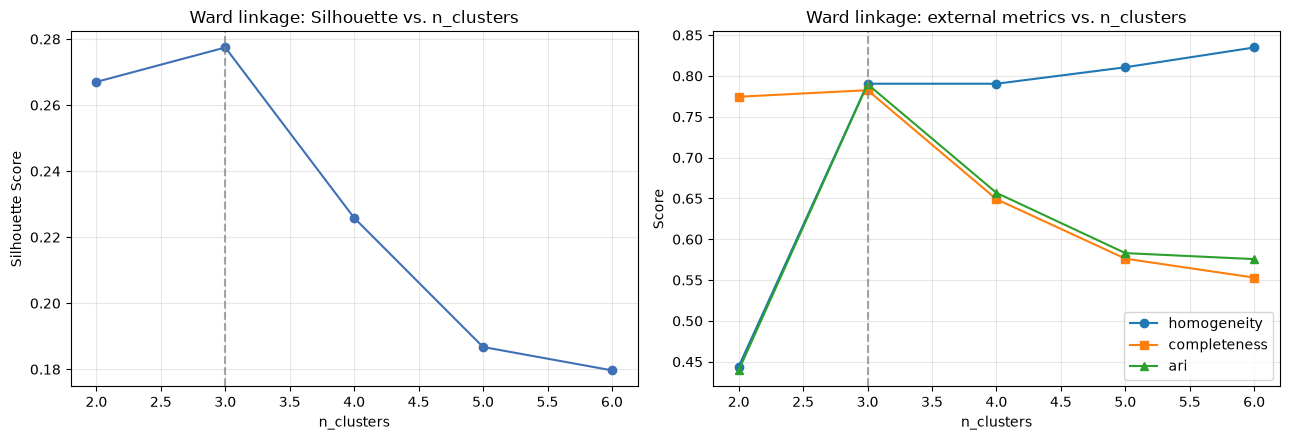

In [12]:
# How each metric responds to n_clusters, holding linkage at 'ward'
ward = hier_results[hier_results['linkage'] == 'ward'].set_index('n_clusters')

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ward.index, ward['silhouette'], 'o-', color='#3f6fb5')
axes[0].set_title('Ward linkage: Silhouette vs. n_clusters')
axes[0].set_xlabel('n_clusters'); axes[0].set_ylabel('Silhouette Score')
axes[0].axvline(3, color='gray', ls='--', alpha=0.7)
axes[0].grid(alpha=0.3)

for col, style in [('homogeneity', 'o-'), ('completeness', 's-'), ('ari', '^-')]:
    axes[1].plot(ward.index, ward[col], style, label=col)
axes[1].set_title('Ward linkage: external metrics vs. n_clusters')
axes[1].set_xlabel('n_clusters'); axes[1].set_ylabel('Score')
axes[1].axvline(3, color='gray', ls='--', alpha=0.7)
axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('hierarchical_metrics.png', dpi=120, bbox_inches='tight')
plt.show()

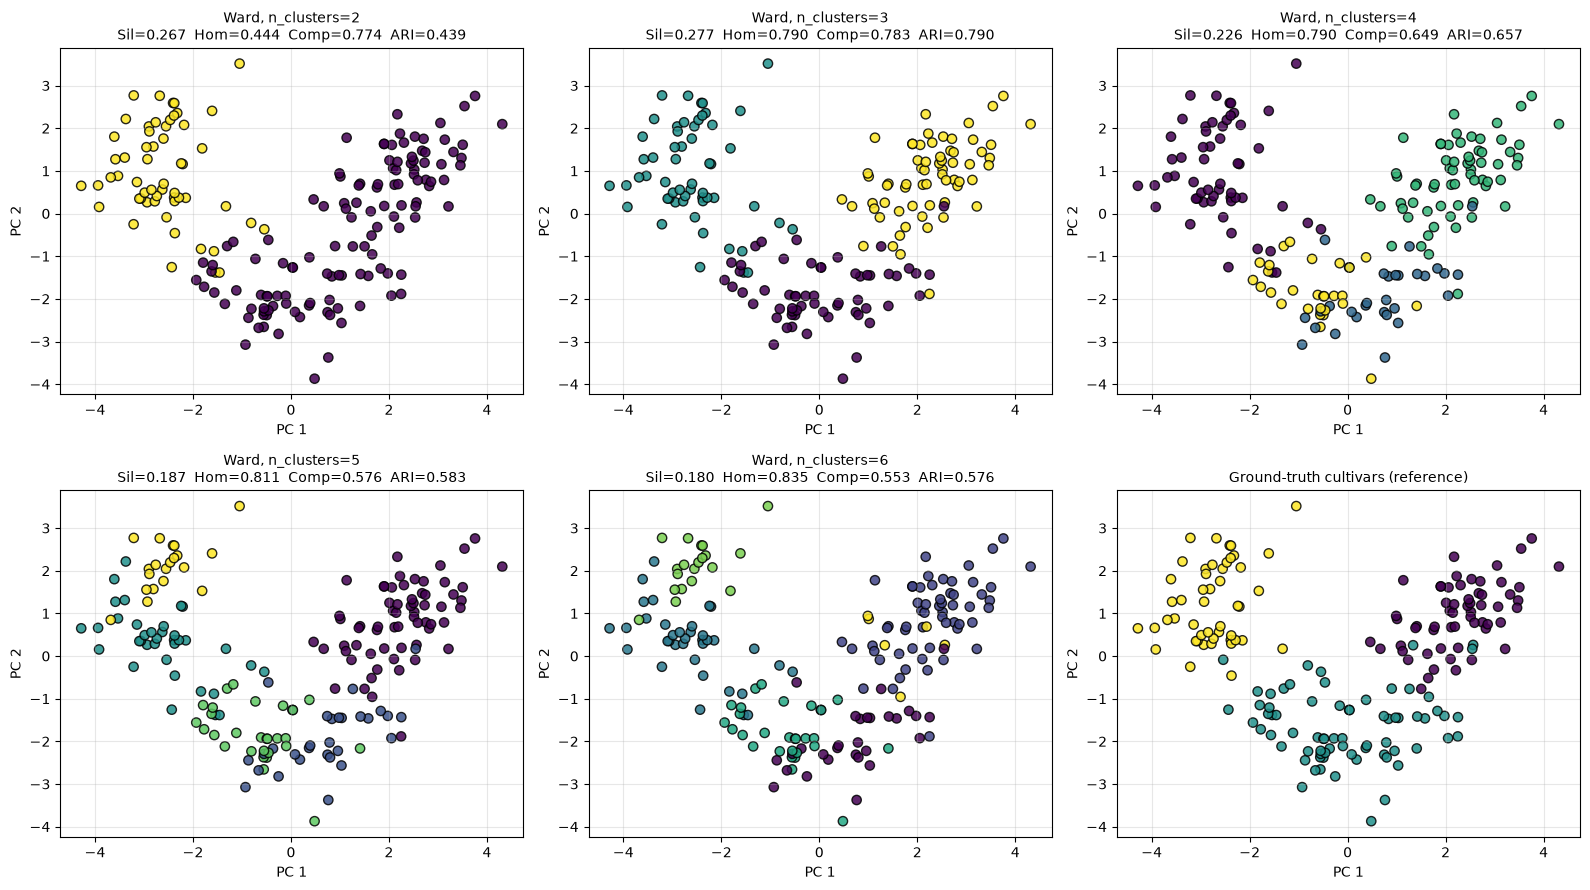

In [13]:
# Visualize the Ward clusters for each n_clusters, with ground truth for reference
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, k in zip(axes.ravel(), range(2, 7)):
    labels = AgglomerativeClustering(n_clusters=k, linkage='ward').fit_predict(X_scaled)
    s = score(labels)
    plot_clusters(ax, labels,
                  f"Ward, n_clusters={k}\nSil={s['silhouette']:.3f}  "
                  f"Hom={s['homogeneity']:.3f}  Comp={s['completeness']:.3f}  ARI={s['ari']:.3f}")

plot_clusters(axes.ravel()[5], y, 'Ground-truth cultivars (reference)')
plt.tight_layout()
plt.savefig('hierarchical_clusters.png', dpi=120, bbox_inches='tight')
plt.show()

`n_clusters=3` is the best Ward solution on every metric that balances the two error types: it has
the highest silhouette and by far the highest ARI. Homogeneity keeps creeping up past k=3 - splitting
a true class into two pure fragments never hurts homogeneity - but completeness falls off sharply,
which is exactly what over-splitting looks like. Reading either external metric alone would be
misleading; they have to be read as a pair.

In [14]:
# Adopt Ward with n_clusters=3 as the final hierarchical model
hier_labels = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_scaled)
hier_score = score(hier_labels)

print("Final hierarchical model - Ward linkage, n_clusters=3")
for k_, v in hier_score.items():
    print(f"  {k_:>20}: {v:.4f}" if isinstance(v, float) else f"  {k_:>20}: {v}")

print("\nCluster sizes:", pd.Series(hier_labels).value_counts().sort_index().to_dict())
print("\nCluster vs. true cultivar:")
pd.crosstab(pd.Series([target_names[i] for i in y], name='true class'),
            pd.Series(hier_labels, name='cluster'))

Final hierarchical model - Ward linkage, n_clusters=3
            n_clusters: 3
               n_noise: 0
            silhouette: 0.2774
   silhouette_no_noise: 0.2774
           homogeneity: 0.7904
          completeness: 0.7825
                   ari: 0.7899

Cluster sizes: {0: 58, 1: 56, 2: 64}

Cluster vs. true cultivar:


cluster,0,1,2
true class,,,
class_0,0,0,59
class_1,58,8,5
class_2,0,48,0


### Dendrogram

The dendrogram shows the whole merge history. The height of each horizontal link is the distance at
which two clusters were joined, so a **tall vertical gap** means the next merge had to bridge a much
larger distance than the previous one - the signature of well-separated groups. Cutting the tree
horizontally anywhere inside such a gap yields a stable cluster count.

In [15]:
# Ward linkage matrix over the standardized features
Z = linkage(X_scaled, method='ward')

# Cophenetic correlation: how faithfully the tree reproduces the original pairwise distances
coph_corr, _ = cophenet(Z, pdist(X_scaled))
print(f"Cophenetic correlation coefficient: {coph_corr:.4f}")

# Merge heights of the final merges - the gaps here are what we cut between
print(f"Heights of the last 8 merges: {np.round(Z[-8:, 2], 3)}")
for k in range(2, 6):
    print(f"  cutting for k={k} clusters requires a threshold between "
          f"{Z[-k, 2]:.2f} and {Z[-(k - 1), 2]:.2f}")

Cophenetic correlation coefficient: 0.6623
Heights of the last 8 merges: [10.155 10.399 11.376 11.722 12.231 12.567 27.652 35.402]
  cutting for k=2 clusters requires a threshold between 27.65 and 35.40
  cutting for k=3 clusters requires a threshold between 12.57 and 27.65
  cutting for k=4 clusters requires a threshold between 12.23 and 12.57
  cutting for k=5 clusters requires a threshold between 11.72 and 12.23


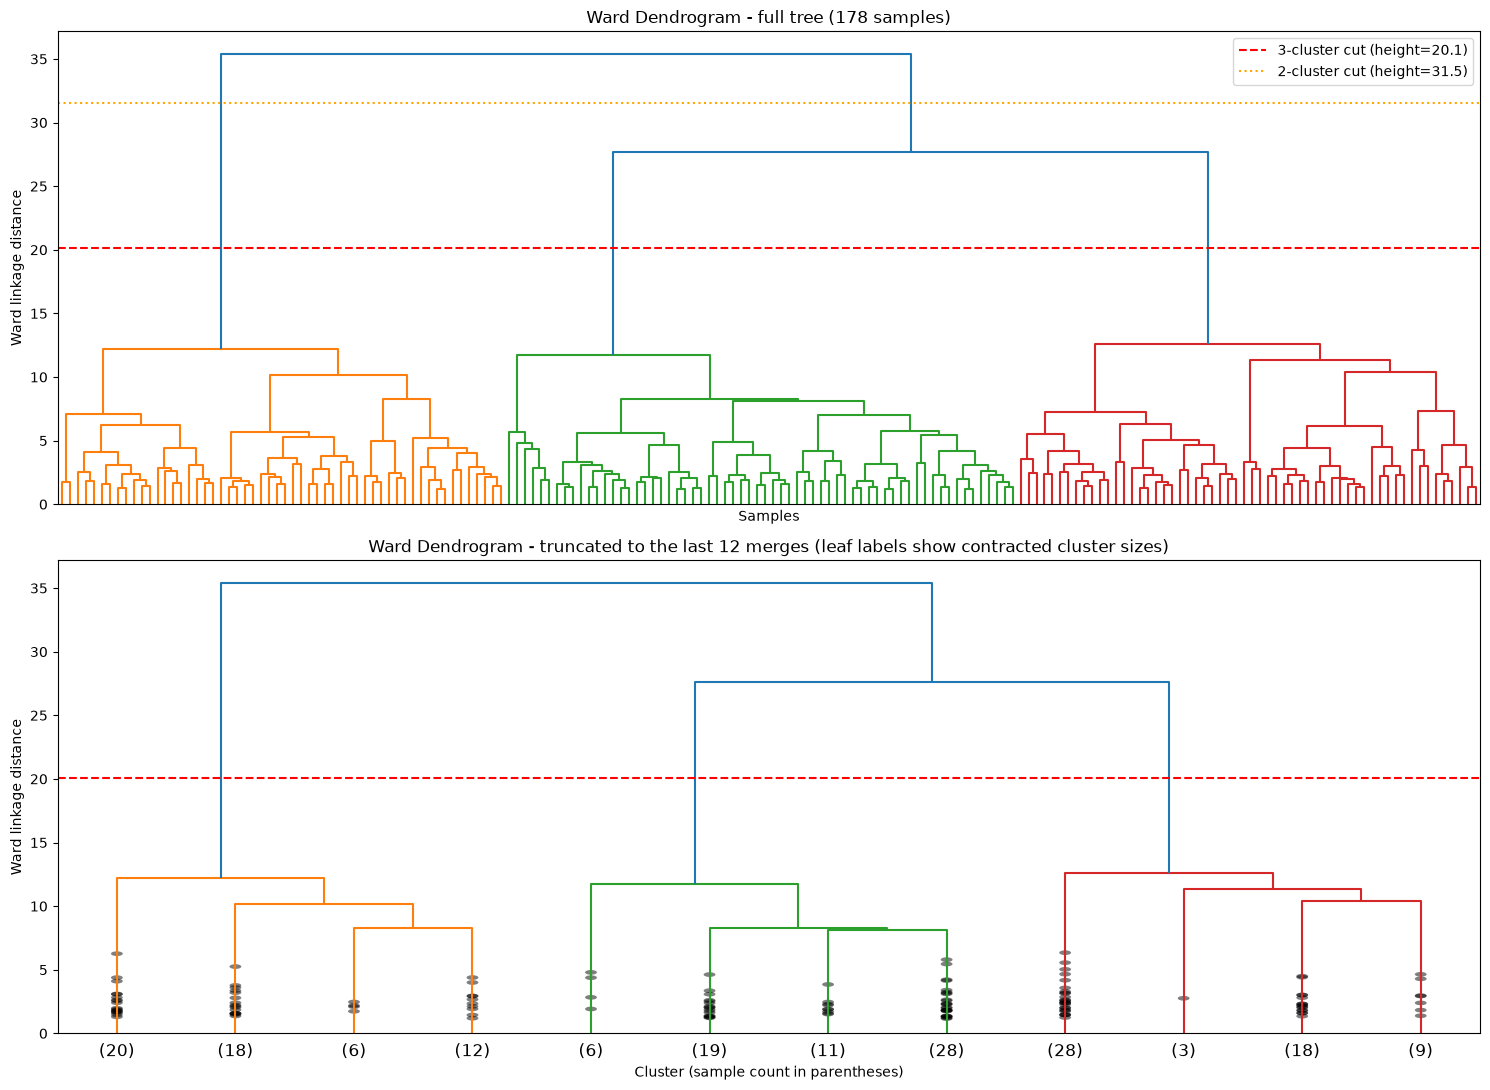

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(15, 11))

# Full dendrogram, colored at the 3-cluster cut
cut_3 = (Z[-3, 2] + Z[-2, 2]) / 2
dendrogram(Z, ax=axes[0], color_threshold=cut_3, no_labels=True)
axes[0].axhline(cut_3, color='red', ls='--',
                label=f'3-cluster cut (height={cut_3:.1f})')
axes[0].axhline((Z[-2, 2] + Z[-1, 2]) / 2, color='orange', ls=':',
                label=f'2-cluster cut (height={(Z[-2, 2] + Z[-1, 2]) / 2:.1f})')
axes[0].set_title('Ward Dendrogram - full tree (178 samples)')
axes[0].set_xlabel('Samples')
axes[0].set_ylabel('Ward linkage distance')
axes[0].legend()

# Truncated view: last 12 merges only, so the top of the tree is readable
dendrogram(Z, ax=axes[1], truncate_mode='lastp', p=12,
           show_leaf_counts=True, show_contracted=True, color_threshold=cut_3)
axes[1].axhline(cut_3, color='red', ls='--')
axes[1].set_title('Ward Dendrogram - truncated to the last 12 merges '
                  '(leaf labels show contracted cluster sizes)')
axes[1].set_xlabel('Cluster (sample count in parentheses)')
axes[1].set_ylabel('Ward linkage distance')

plt.tight_layout()
plt.savefig('dendrogram.png', dpi=120, bbox_inches='tight')
plt.show()

**Interpretation.** The tree is dominated by two enormous jumps at the top: the final merge happens
at a height of about 35.4 and the one before it at about 27.7, whereas the next merge down sits at
only 12.6. That is a factor-of-two gap, and it is the clearest structural signal in the dataset -
three groups genuinely separate before anything else does. Below a height of roughly 12 the merge
heights become dense and gradual, meaning further splits are carving up continuous within-group
variation rather than finding real boundaries.

The three-cluster cut also gives sensible sizes (59 / 71 / 48) that mirror the true cultivar counts
(59 / 71 / 48). The cophenetic correlation of 0.66 is moderate: the tree captures the broad distance
structure but flattens finer detail, which is expected in 13 dimensions where most pairwise
distances are similar.

## Step 3: DBSCAN Clustering

DBSCAN needs two parameters:

- **`eps`** - the neighborhood radius.
- **`min_samples`** - how many points must fall inside that radius for a point to be a *core* point.

A standard heuristic for `eps` is the **k-distance plot**: sort every point by its distance to its
k-th nearest neighbor (k = `min_samples`) and look for the "elbow", where distances start climbing
steeply. Points to the right of the elbow are the sparse ones DBSCAN will call noise.

min_samples= 3  median k-dist=1.93  90th pct=2.83  max=4.53
min_samples= 5  median k-dist=2.22  90th pct=3.13  max=5.02
min_samples=10  median k-dist=2.56  90th pct=3.55  max=5.40
min_samples=15  median k-dist=2.80  90th pct=3.73  max=5.70


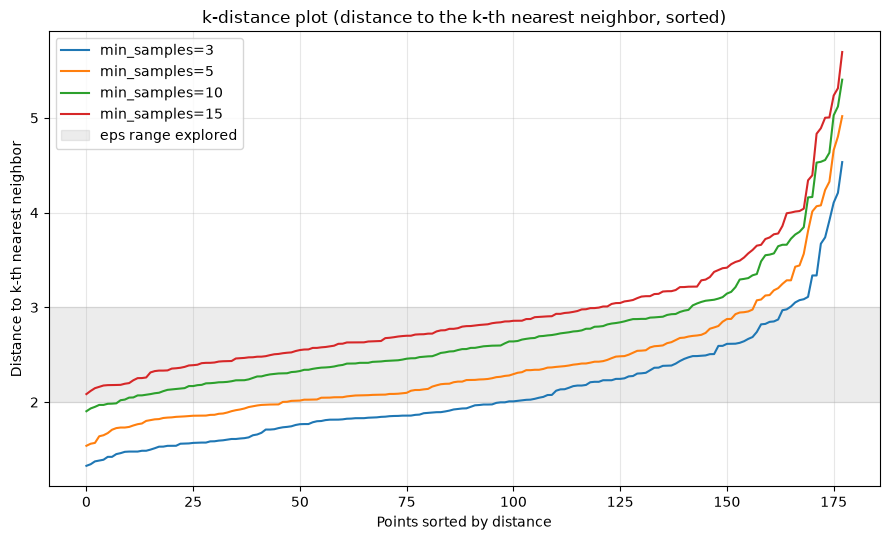

In [17]:
# k-distance curves to bracket a sensible eps range
fig, ax = plt.subplots(figsize=(9, 5.5))
for ms in [3, 5, 10, 15]:
    dists, _ = NearestNeighbors(n_neighbors=ms).fit(X_scaled).kneighbors(X_scaled)
    kth = np.sort(dists[:, -1])
    ax.plot(kth, label=f'min_samples={ms}')
    print(f"min_samples={ms:>2}  median k-dist={np.median(kth):.2f}  "
          f"90th pct={np.percentile(kth, 90):.2f}  max={kth.max():.2f}")

ax.axhspan(2.0, 3.0, color='gray', alpha=0.15, label='eps range explored')
ax.set_title('k-distance plot (distance to the k-th nearest neighbor, sorted)')
ax.set_xlabel('Points sorted by distance')
ax.set_ylabel('Distance to k-th nearest neighbor')
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('k_distance_plot.png', dpi=120, bbox_inches='tight')
plt.show()

The curves rise smoothly with no sharp elbow - the first warning sign that this dataset is not
strongly density-structured. Standardizing 13 features spreads the samples out so that
nearest-neighbor distances are all broadly comparable (median 1.9-2.8 depending on k), which is the
regime where DBSCAN struggles. The curves do tell us the useful `eps` window is roughly 1.5-3.5:
below that everything is noise, above it everything collapses into one cluster.

In [18]:
# Grid search over eps x min_samples
eps_values = [1.5, 1.75, 2.0, 2.2, 2.4, 2.5, 2.75, 3.0, 3.5]
min_samples_values = [3, 5, 8, 10, 15]

rows = []
for eps in eps_values:
    for ms in min_samples_values:
        labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
        rows.append({'eps': eps, 'min_samples': ms, **score(labels)})

dbscan_results = pd.DataFrame(rows)
dbscan_results['noise_pct'] = (dbscan_results['n_noise'] / len(X_scaled) * 100).round(1)
dbscan_results = dbscan_results[['eps', 'min_samples', 'n_clusters', 'n_noise', 'noise_pct',
                                 'silhouette', 'silhouette_no_noise',
                                 'homogeneity', 'completeness', 'ari']]
dbscan_results.round(4)

,eps,min_samples,n_clusters,n_noise,noise_pct,silhouette,silhouette_no_noise,homogeneity,completeness,ari
0,1.50,3,8,147,82.6,-0.2768,0.3311,0.1892,0.2510,0.0403
1,1.50,5,0,178,100.0,NaN,NaN,0.0000,1.0000,0.0000
2,1.50,8,0,178,100.0,NaN,NaN,0.0000,1.0000,0.0000
3,1.50,10,0,178,100.0,NaN,NaN,0.0000,1.0000,0.0000
4,1.50,15,0,178,100.0,NaN,NaN,0.0000,1.0000,0.0000
5,1.75,3,11,98,55.1,-0.1247,0.2054,0.4810,0.3124,0.1337
6,1.75,5,6,132,74.2,-0.2080,0.3129,0.2633,0.2833,0.0391
7,1.75,8,0,178,100.0,NaN,NaN,0.0000,1.0000,0.0000
8,1.75,10,0,178,100.0,NaN,NaN,0.0000,1.0000,0.0000
9,1.75,15,0,178,100.0,NaN,NaN,0.0000,1.0000,0.0000


In [19]:
# The same grid as pivot tables, which makes the parameter effects easier to read
print("Number of clusters found (rows = eps, cols = min_samples):")
print(dbscan_results.pivot(index='eps', columns='min_samples', values='n_clusters'))

print("\nPercentage of points labeled as noise:")
print(dbscan_results.pivot(index='eps', columns='min_samples', values='noise_pct'))

print("\nSilhouette Score (noise treated as its own label; NaN = fewer than 2 groups):")
print(dbscan_results.pivot(index='eps', columns='min_samples', values='silhouette').round(3))

Number of clusters found (rows = eps, cols = min_samples):
min_samples  3   5   8   10  15
eps                            
1.50          8   0   0   0   0
1.75         11   6   0   0   0
2.00          5   5   3   1   0
2.20          3   2   2   2   2
2.40          2   2   2   2   2
2.50          1   1   2   2   2
2.75          1   1   1   1   2
3.00          2   1   1   1   1
3.50          2   1   1   1   1

Percentage of points labeled as noise:
min_samples    3      5      8      10     15
eps                                          
1.50         82.6  100.0  100.0  100.0  100.0
1.75         55.1   74.2  100.0  100.0  100.0
2.00         36.0   47.8   65.7   78.1  100.0
2.20         24.7   30.9   37.6   50.0   65.7
2.40         15.7   20.2   24.2   27.5   44.9
2.50         12.9   13.5   16.9   18.0   28.7
2.75          9.0    9.6   11.2   11.2   14.0
3.00          3.9    6.2    6.2    6.7    7.3
3.50          1.7    3.4    3.9    4.5    5.1

Silhouette Score (noise treated as its own

In [20]:
# Select the best DBSCAN run: highest silhouette among runs that actually found >= 2 clusters
valid = dbscan_results[dbscan_results['n_clusters'] >= 2].copy()
best_row = valid.loc[valid['silhouette'].idxmax()]
print("Best DBSCAN configuration by Silhouette Score:")
print(best_row.round(4))

print("\nRunner-up configurations:")
valid.sort_values('silhouette', ascending=False).head(5).round(4)

Best DBSCAN configuration by Silhouette Score:
eps                     2.7500
min_samples            15.0000
n_clusters              2.0000
n_noise                25.0000
noise_pct              14.0000
silhouette              0.2246
silhouette_no_noise     0.3115
homogeneity             0.4981
completeness            0.5808
ari                     0.4225
Name: 34, dtype: float64

Runner-up configurations:


,eps,min_samples,n_clusters,n_noise,noise_pct,silhouette,silhouette_no_noise,homogeneity,completeness,ari
34,2.75,15,2,25,14.0,0.2246,0.3115,0.4981,0.5808,0.4225
40,3.50,3,2,3,1.7,0.2164,0.2308,0.0293,0.1866,-0.0093
20,2.40,3,2,28,15.7,0.2144,0.3142,0.4871,0.5491,0.4171
27,2.50,8,2,30,16.9,0.2076,0.3183,0.4837,0.5448,0.4129
28,2.50,10,2,32,18.0,0.2044,0.3228,0.5045,0.5604,0.4235


**A caution about selecting on silhouette alone.** The runner-up here is `eps=3.5, min_samples=3`,
whose silhouette (0.216) is only marginally below the winner's (0.225) - yet it is a *degenerate*
solution: 172 points in one cluster, 3 in another, and homogeneity of 0.03. Silhouette is perfectly
happy with "one blob plus a speck" because that partition is trivially well-separated. This is why
the external metrics matter: they immediately expose the degenerate run, and they are the reason the
selected configuration is trustworthy while the near-tie is not.

In [21]:
# Adopt the best configuration as the final DBSCAN model
best_eps = float(best_row['eps'])
best_min_samples = int(best_row['min_samples'])

dbscan = DBSCAN(eps=best_eps, min_samples=best_min_samples)
dbscan_labels = dbscan.fit_predict(X_scaled)
dbscan_score = score(dbscan_labels)

print(f"Final DBSCAN model - eps={best_eps}, min_samples={best_min_samples}\n")
print(f"  Clusters found          : {dbscan_score['n_clusters']}")
print(f"  Noise points            : {dbscan_score['n_noise']} "
      f"({dbscan_score['n_noise'] / len(X_scaled):.1%} of the data)")
print(f"  Core samples            : {len(dbscan.core_sample_indices_)}")
print(f"  Silhouette Score        : {dbscan_score['silhouette']:.4f}  "
      f"(noise as its own label)")
print(f"  Silhouette (no noise)   : {dbscan_score['silhouette_no_noise']:.4f}")
print(f"  Homogeneity Score       : {dbscan_score['homogeneity']:.4f}")
print(f"  Completeness Score      : {dbscan_score['completeness']:.4f}")
print(f"  Adjusted Rand Index     : {dbscan_score['ari']:.4f}")

print("\nCluster sizes (-1 = noise):",
      pd.Series(dbscan_labels).value_counts().sort_index().to_dict())
print("\nCluster vs. true cultivar:")
pd.crosstab(pd.Series([target_names[i] for i in y], name='true class'),
            pd.Series(dbscan_labels, name='cluster'))

Final DBSCAN model - eps=2.75, min_samples=15

  Clusters found          : 2
  Noise points            : 25 (14.0% of the data)
  Core samples            : 83
  Silhouette Score        : 0.2246  (noise as its own label)
  Silhouette (no noise)   : 0.3115
  Homogeneity Score       : 0.4981
  Completeness Score      : 0.5808
  Adjusted Rand Index     : 0.4225

Cluster sizes (-1 = noise): {-1: 25, 0: 107, 1: 46}

Cluster vs. true cultivar:


cluster,-1,0,1
true class,,,
class_0,1,58,0
class_1,20,49,2
class_2,4,0,44


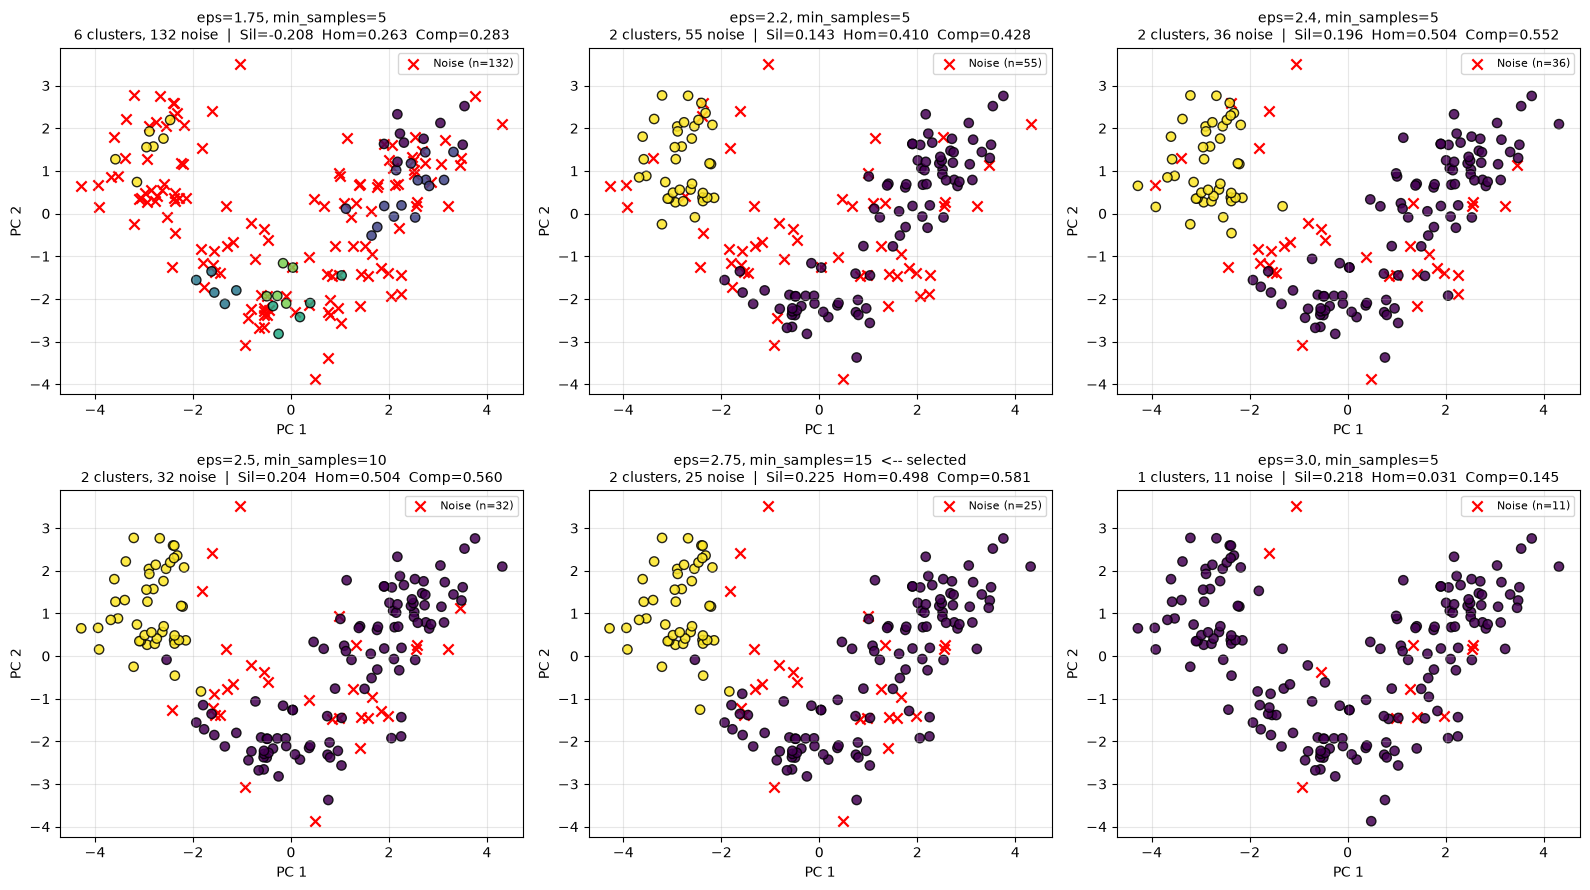

In [22]:
# Effect of eps and min_samples, visualized. Red X = noise.
combos = [(1.75, 5), (2.2, 5), (2.4, 5), (2.5, 10),
          (best_eps, best_min_samples), (3.0, 5)]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for ax, (eps, ms) in zip(axes.ravel(), combos):
    labels = DBSCAN(eps=eps, min_samples=ms).fit_predict(X_scaled)
    s = score(labels)
    sil = f"{s['silhouette']:.3f}" if not np.isnan(s['silhouette']) else 'n/a'
    tag = '  <-- selected' if (eps, ms) == (best_eps, best_min_samples) else ''
    plot_clusters(ax, labels,
                  f"eps={eps}, min_samples={ms}{tag}\n"
                  f"{s['n_clusters']} clusters, {s['n_noise']} noise  |  Sil={sil}  "
                  f"Hom={s['homogeneity']:.3f}  Comp={s['completeness']:.3f}")

plt.tight_layout()
plt.savefig('dbscan_clusters.png', dpi=120, bbox_inches='tight')
plt.show()

The progression is the whole story of DBSCAN's parameters. At `eps=1.75` the radius is smaller than
typical nearest-neighbor distances, so DBSCAN shatters the data into 6 fragments and discards 132 of
178 points as noise. As `eps` grows the fragments fuse and the noise set shrinks. By `eps=3.0` the
radius spans the gap between the true cultivars and everything collapses into a single cluster with
a handful of outliers - the clustering has become meaningless even though only 11 points are noise.
The usable window is narrow, and `min_samples` shifts the same trade-off in the opposite direction:
raising it makes core points harder to qualify, which fragments clusters and grows the noise set at
any fixed `eps`.

## Step 4: Analysis and Insights

In [23]:
# Side-by-side comparison of the two final models
comparison = pd.DataFrame([
    {'Algorithm': 'Hierarchical (Ward, k=3)', **hier_score},
    {'Algorithm': f'DBSCAN (eps={best_eps}, min_samples={best_min_samples})', **dbscan_score},
]).set_index('Algorithm')
comparison.round(4)

,n_clusters,n_noise,silhouette,silhouette_no_noise,homogeneity,completeness,ari
Algorithm,,,,,,,
"Hierarchical (Ward, k=3)",3,0,0.2774,0.2774,0.7904,0.7825,0.7899
"DBSCAN (eps=2.75, min_samples=15)",2,25,0.2246,0.3115,0.4981,0.5808,0.4225


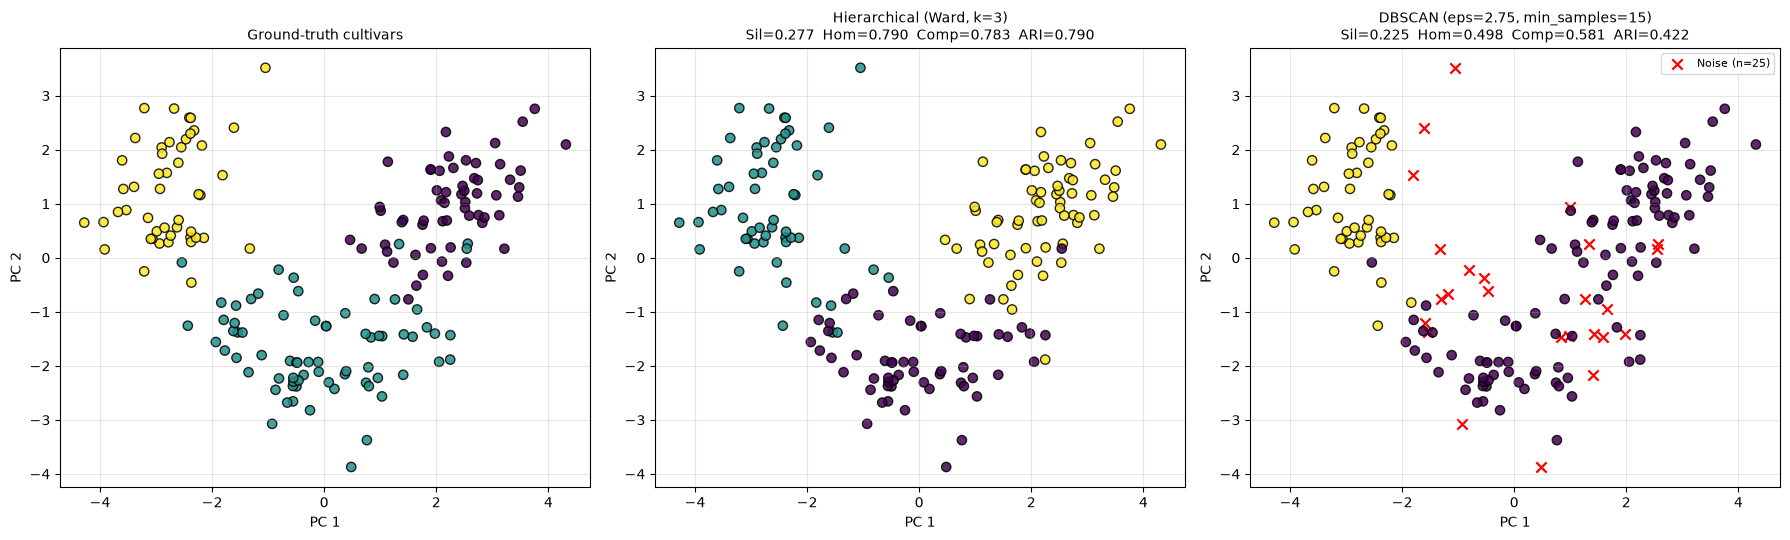

In [24]:
# Final visual comparison against the ground truth
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

plot_clusters(axes[0], y, 'Ground-truth cultivars')
plot_clusters(axes[1], hier_labels,
              f"Hierarchical (Ward, k=3)\nSil={hier_score['silhouette']:.3f}  "
              f"Hom={hier_score['homogeneity']:.3f}  Comp={hier_score['completeness']:.3f}  "
              f"ARI={hier_score['ari']:.3f}")
plot_clusters(axes[2], dbscan_labels,
              f"DBSCAN (eps={best_eps}, min_samples={best_min_samples})\n"
              f"Sil={dbscan_score['silhouette']:.3f}  "
              f"Hom={dbscan_score['homogeneity']:.3f}  "
              f"Comp={dbscan_score['completeness']:.3f}  "
              f"ARI={dbscan_score['ari']:.3f}")

plt.tight_layout()
plt.savefig('cluster_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

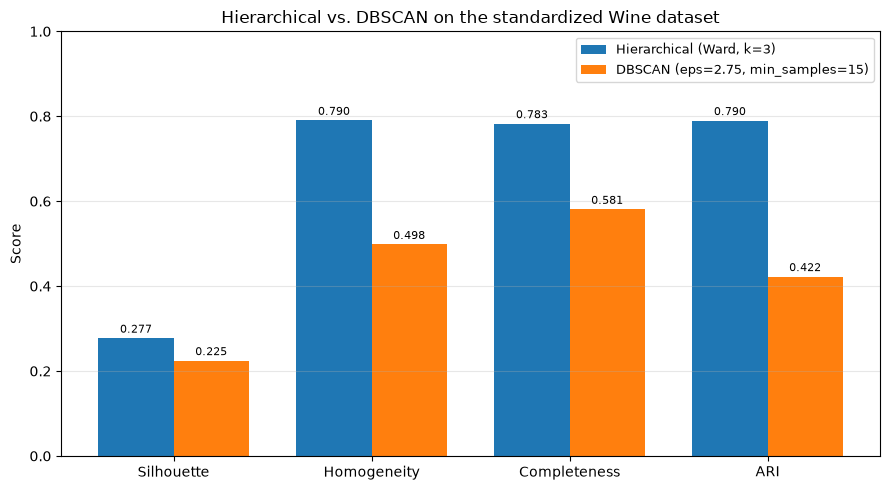

In [25]:
# Metric comparison as a bar chart
metrics = ['silhouette', 'homogeneity', 'completeness', 'ari']
labels_ = ['Silhouette', 'Homogeneity', 'Completeness', 'ARI']
x = np.arange(len(metrics))
width = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
for i, (name, row) in enumerate(comparison.iterrows()):
    vals = [row[m] for m in metrics]
    bars = ax.bar(x + (i - 0.5) * width, vals, width, label=name)
    ax.bar_label(bars, fmt='%.3f', fontsize=8, padding=2)

ax.set_xticks(x, labels_)
ax.set_ylabel('Score')
ax.set_ylim(0, 1.0)
ax.set_title('Hierarchical vs. DBSCAN on the standardized Wine dataset')
ax.legend(fontsize=9)
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.savefig('metric_comparison.png', dpi=120, bbox_inches='tight')
plt.show()

### Comparing the two algorithms

**Hierarchical clustering (Ward, k=3) wins decisively on every metric.**

| Metric | Hierarchical (Ward, k=3) | DBSCAN (eps=2.75, min_samples=15) |
|---|---|---|
| Silhouette | **0.277** | 0.225 |
| Homogeneity | **0.790** | 0.498 |
| Completeness | **0.783** | 0.581 |
| ARI | **0.790** | 0.423 |
| Clusters found | 3 (specified) | 2 (discovered) |
| Noise points | 0 | 25 (14%) |

The confusion tables explain the gap. Ward recovers the three cultivars almost exactly - clusters of
58 / 56 / 64 against true counts of 59 / 71 / 48, with only 13 of 178 samples misassigned, all of
them from `class_1`, the cultivar that sits between the other two. DBSCAN never separates `class_0`
from `class_1` at all: its large cluster contains 58 `class_0` and 49 `class_1` samples, it isolates
`class_2` cleanly (44 of 48), and it discards 25 points as noise - 20 of which are `class_1`.

The reason is structural. DBSCAN can only split two groups if there is a genuine **density valley**
between them, and in the 13-dimensional standardized space there is no such valley between cultivars
0 and 1 - they form one continuous dense region. The k-distance plot predicted this: no elbow means
no natural density threshold. Ward, by contrast, does not need a valley. It only needs the
*within*-group variance to be smaller than the *between*-group variance, which is true here, so it
finds the boundary that DBSCAN cannot see.

DBSCAN's two low external scores fail in different ways and both matter. Low **homogeneity** (0.498)
means its clusters mix classes - the big cluster holds two cultivars. Low **completeness** (0.581)
means members of one class are scattered - `class_1` is split between the big cluster and the noise
set. Neither metric alone tells the whole story, which is precisely why the assignment asks for both.

### How parameter choices drove the results

**Hierarchical - `n_clusters` and linkage:**

- `n_clusters` is chosen *after* fitting, by cutting the dendrogram, so one linkage matrix supports
  every k. The dendrogram made the choice nearly automatic: merge heights of 35.4 and 27.7 at the
  top versus 12.6 for the next merge is an unambiguous three-cluster signal.
- Going past k=3 pushed homogeneity *up* (0.790 → 0.835 at k=6) while completeness *collapsed*
  (0.783 → 0.553). This is the over-splitting signature, and it is why homogeneity must never be
  optimized on its own - a clustering with one point per cluster scores a perfect 1.0.
- **Linkage mattered more than k.** Ward at k=3 scored ARI = 0.790; `complete` linkage reached only
  0.577, and `average` and `single` linkage collapsed to ARI ≈ 0.0 at k=3, producing one giant
  cluster plus a few singletons. Single linkage chains through the continuum between cultivars 0 and
  1 for the same reason DBSCAN does - both propagate connectivity through nearest neighbors. Ward's
  variance-minimizing criterion is what makes it immune to that failure mode.

**DBSCAN - `eps` and `min_samples`:**

- `eps` controls everything, and the working window was narrow. At `eps ≤ 1.25` every point was
  noise, regardless of `min_samples`. At `eps = 1.75` the result was 6 fragments and 132 noise
  points. Between 2.2 and 2.75 there were two sensible clusters. By `eps = 3.0` everything merged
  into one cluster. The entire useful range spans about 0.5 units of distance.
- `min_samples` acts in the opposite direction: raising it at fixed `eps` makes core points harder to
  qualify, so clusters fragment and noise grows. At `eps = 2.4`, going from `min_samples = 3` to 15
  raised the noise count from 28 to 80 while both external metrics fell.
- The two parameters interact rather than tune independently, which is DBSCAN's practical weakness -
  a 45-point grid was needed to find a defensible setting, and even the winner recovers only 2 of 3
  cultivars.

### Strengths and weaknesses observed in this lab

**Hierarchical clustering**

*Strengths:* the dendrogram is a genuine analysis tool - it revealed the correct cluster count from
the data rather than requiring a guess, and it exposes structure at every scale simultaneously. Ward
handled the touching, elongated cultivar groups without difficulty and assigned every point, which
is what you want when the data has no true outliers. It is also deterministic: no random
initialization, so results are exactly reproducible.

*Weaknesses:* it forces every point into a cluster, so a genuine outlier necessarily corrupts some
cluster. Merges are greedy and irreversible - a bad early merge can never be undone. It costs O(n²)
memory for the distance matrix, which is fine for 178 samples but rules it out for large datasets.
And the results depend heavily on the linkage rule, as the ARI spread from 0.79 down to 0.0 across
linkages shows.

**DBSCAN**

*Strengths:* it discovered the cluster count on its own and explicitly separated 25 low-density
points as noise instead of forcing them into a cluster. It is the right tool for arbitrarily shaped
(non-convex) clusters and for data with real outliers, and its noise labels are informative in their
own right - the 20 `class_1` points it rejected really do sit in the sparse transition zone between
the other two cultivars.

*Weaknesses:* it is very sensitive to `eps`, needs a joint 2D parameter search, and - most
importantly here - it assumes clusters are separated by density gaps. That assumption simply does not
hold for this dataset. It also uses one global `eps`, so it cannot adapt to clusters of differing
density, and in 13 dimensions the concentration of pairwise distances erodes the density contrast it
depends on.

### Conclusion

**For the standardized Wine dataset, Agglomerative Hierarchical Clustering with Ward linkage and
k=3 is clearly the better choice**, achieving ARI = 0.790 against DBSCAN's 0.423 and recovering all
three cultivars where DBSCAN recovered two. The result is not a statement about which algorithm is
better in general - it is a statement about this data. The Wine cultivars form compact,
roughly convex, contiguous groups with no density gaps and no meaningful outliers, which is exactly
the setting Ward is built for and exactly the setting in which DBSCAN has nothing to grip. On data
with irregular cluster shapes, real outliers, or an unknown number of well-separated dense regions,
the ranking would very plausibly reverse.